In [1]:
'''Apply SHAP (SHapley Additive exPlanations) values to interpret complex model predictions and explain individual applicant decisions, ensuring transparency and accountability in admissions.'''

'Apply SHAP (SHapley Additive exPlanations) values to interpret complex model predictions and explain individual applicant decisions, ensuring transparency and accountability in admissions.'

In [2]:
# import libraries and load dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shap
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

df = pd.read_csv('Adm.csv')
df.head()

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit,Application_DateTime,University_Name,region
0,1,337,118,4,4.5,4.5,9.65,1,0.96,2022-01-01 09:00:00,Indian Institute of Technology Kharagpur,East
1,2,324,107,4,4.0,4.5,8.87,1,0.80,2022-01-02 09:00:00,National Institute of Technology Karnataka,South
2,3,316,104,3,3.0,3.5,8.00,1,0.67,2022-01-04 09:00:00,Gujarat University,West
3,4,322,110,3,3.5,2.5,8.67,1,0.78,2022-01-06 09:00:00,Jamia Millia Islamia,North
4,5,314,103,2,2.0,3.0,8.21,0,0.63,2022-01-08 09:00:00,Jamia Millia Islamia,North


In [3]:
# prepare features and train test split
features = ['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research']
target = 'Chance of Admit'

X = df[features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('Training count:', len(X_train), 'Test count:', len(X_test))

Training count: 800 Test count: 200


In [4]:
# train complex random forest model and evaluate
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print('Test R2 Score:', round(r2_score(y_test, y_pred), 3))
print('Test MSE:', round(mean_squared_error(y_test, y_pred), 4))

Test R2 Score: 0.908
Test MSE: 0.0009


In [5]:
# compute shap values with tree explainer
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test)

print('Base value (average admission chance):', round(float(explainer.expected_value[0]), 3))

Base value (average admission chance): 0.717


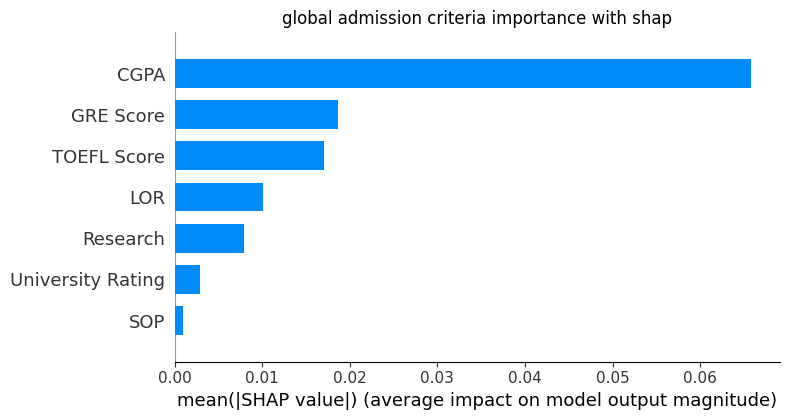

In [6]:
# plot global feature importance using shap bar plot
plt.figure()
shap.summary_plot(shap_values, X_test, plot_type='bar', show=False)
plt.title('global admission criteria importance with shap')
plt.tight_layout()
plt.show()

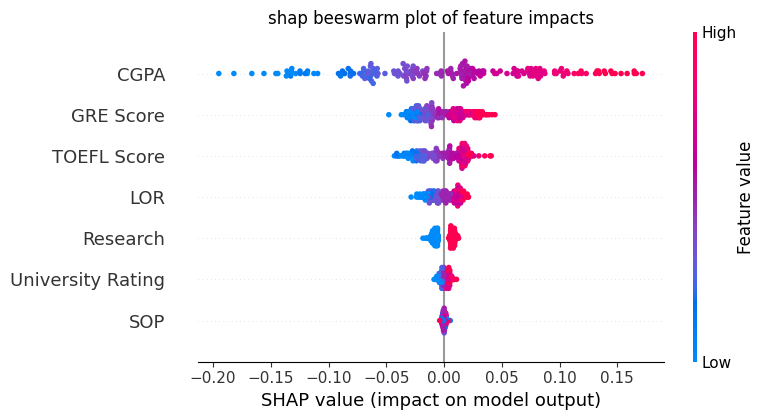

In [7]:
# plot shap summary beeswarm for criteria impact distribution
plt.figure()
shap.summary_plot(shap_values, X_test, show=False)
plt.title('shap beeswarm plot of feature impacts')
plt.tight_layout()
plt.show()

C:\Users\Lenovo\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(


Admitted applicant index: 194 Predicted Chance: 0.958


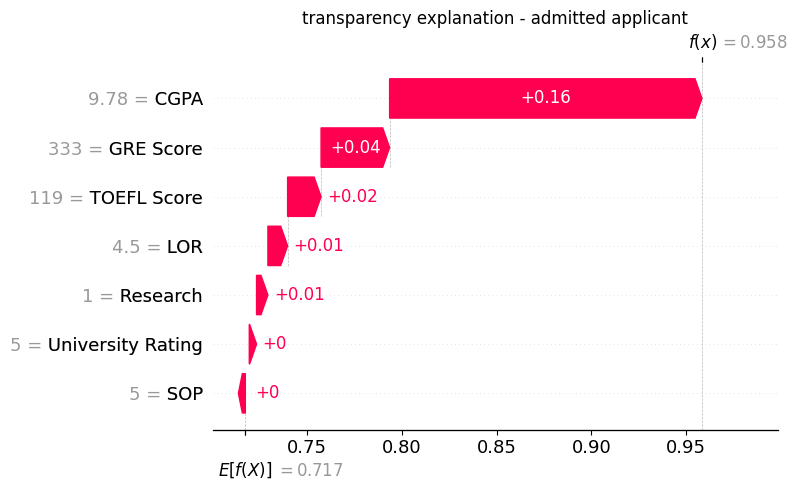

In [8]:
# explain individual decision for admitted applicant with waterfall plot
admit_idx = y_test.argmax()
pred_admit = model.predict([X_test.iloc[admit_idx]])[0]
print('Admitted applicant index:', admit_idx, 'Predicted Chance:', round(pred_admit, 3))

shap.plots.waterfall(shap_values[admit_idx], show=False)
plt.title('transparency explanation - admitted applicant')
plt.tight_layout()
plt.show()

C:\Users\Lenovo\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(


Borderline applicant index: 64 Predicted Chance: 0.692


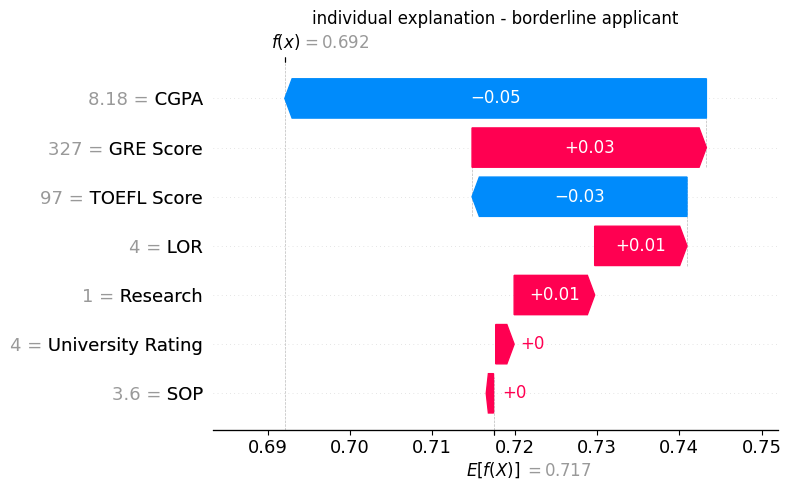

In [9]:
# explain individual decision for borderline applicant with waterfall plot
border_idx = (y_test - 0.70).abs().argmin()
pred_border = model.predict([X_test.iloc[border_idx]])[0]
print('Borderline applicant index:', border_idx, 'Predicted Chance:', round(pred_border, 3))

shap.plots.waterfall(shap_values[border_idx], show=False)
plt.title('individual explanation - borderline applicant')
plt.tight_layout()
plt.show()

C:\Users\Lenovo\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(


Rejected applicant index: 33 Predicted Chance: 0.52


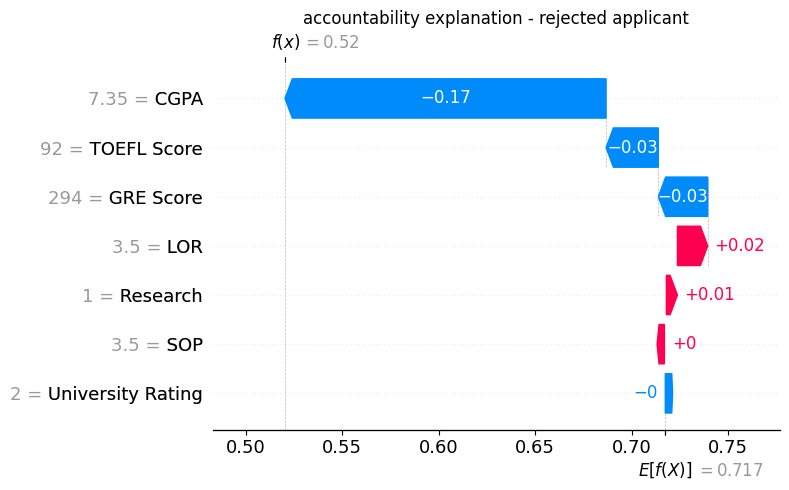

In [10]:
# explain individual decision for rejected applicant with waterfall plot
reject_idx = y_test.argmin()
pred_reject = model.predict([X_test.iloc[reject_idx]])[0]
print('Rejected applicant index:', reject_idx, 'Predicted Chance:', round(pred_reject, 3))

shap.plots.waterfall(shap_values[reject_idx], show=False)
plt.title('accountability explanation - rejected applicant')
plt.tight_layout()
plt.show()

In [11]:
# summarize individual criteria contributions for transparency
transparency_df = pd.DataFrame({
    'Criteria': features,
    'Admitted SHAP': shap_values[admit_idx].values.round(3),
    'Borderline SHAP': shap_values[border_idx].values.round(3),
    'Rejected SHAP': shap_values[reject_idx].values.round(3)
})
transparency_df

,Criteria,Admitted SHAP,Borderline SHAP,Rejected SHAP
0,GRE Score,0.036,0.028,-0.026
1,TOEFL Score,0.018,-0.026,-0.027
2,University Rating,0.004,0.002,-0.000
3,SOP,0.002,0.000,0.001
4,LOR,0.010,0.011,0.016
5,CGPA,0.165,-0.051,-0.166
6,Research,0.006,0.010,0.006
